# Implementación de los tres modelos

El código de los modelos está en `src/modelos.py` y la preparación de datos en `src/datos.py`. Todos los modelos
comparten la misma entrada ($168 \times 4$), la misma pérdida (MSE), el mismo optimizador (Adam), lotes de 1024
ventanas y parada temprana por el RMSE de validación (2024). La prueba (2025) no se usa en este capítulo.

In [1]:
import json, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
fuente = open("src/modelos.py", encoding="utf-8").read()
print(fuente[fuente.index("class MLP"):fuente.index("MODELOS =")])

class MLP(nn.Module):
    def __init__(self, L, d, h1=256, h2=128, dropout=0.1):
        super().__init__()
        self.f = nn.Sequential(nn.Flatten(), nn.Linear(L * d, h1), nn.ReLU(), nn.Dropout(dropout),
                               nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(h2, 1))

    def forward(self, x):
        return self.f(x).squeeze(-1)


class LSTM(nn.Module):
    def __init__(self, L, d, h=64, capas=1, dropout=0.0):
        super().__init__()
        self.r = nn.LSTM(d, h, num_layers=capas, batch_first=True, dropout=dropout if capas > 1 else 0.0)
        self.o = nn.Linear(h, 1)

    def forward(self, x):
        return self.o(self.r(x)[0][:, -1]).squeeze(-1)       # estado oculto de la última hora


class CNN(nn.Module):
    def __init__(self, L, d, c1=32, c2=64, k=5, dropout=0.1):
        super().__init__()
        self.f = nn.Sequential(nn.Conv1d(d, c1, k, padding=k // 2), nn.ReLU(), nn.MaxPool1d(2),
                               nn.Conv1d(c1, c2, 

## Control de la aleatoriedad

Cada corrida fija la semilla de Python, NumPy y PyTorch (CPU y GPU) y activa el modo determinista de cuDNN
(`modelos.fijar_semilla`). El orden de los lotes también sale de un generador con la misma semilla. Así, una
corrida con la misma semilla y el mismo hardware reproduce el mismo resultado.

## Piloto: variabilidad entre semillas y número de corridas

Se entrenó cada modelo con 5 semillas y la configuración inicial, evaluando solo en validación.

In [2]:
pil = pd.DataFrame(json.load(open("resultados/piloto.json")))
print(pil.groupby("modelo").agg(RMSE_val_media=("rmse_val", "mean"), RMSE_val_de=("rmse_val", "std"),
                                epocas=("epocas", "mean"), segundos=("segundos", "mean")).round(4))
ancho = pil.pivot(index="semilla", columns="modelo", values="rmse_val")
sig_d = {f"{a} − {b}": (ancho[a] - ancho[b]).std(ddof=1)
         for i, a in enumerate(ancho) for b in list(ancho)[i + 1:]}
print("\nDesviación estándar de la diferencia pareada por semilla (σ_d):")
for k, v in sig_d.items():
    print(f"  {k}: {v:.4f}")

        RMSE_val_media  RMSE_val_de  epocas  segundos
modelo                                               
CNN             0.7961       0.0023    17.8   34.2946
LSTM            0.7933       0.0022    15.4   56.9022
MLP             0.8007       0.0014     8.8    4.4772

Desviación estándar de la diferencia pareada por semilla (σ_d):
  CNN − LSTM: 0.0038
  CNN − MLP: 0.0024
  LSTM − MLP: 0.0030


Para detectar una diferencia de $\delta = 0.02$ m/s con $\alpha = 0.05$ (bilateral) y potencia del 80 %, el número
de semillas por modelo es

$$R \approx \frac{(z_{0.975} + z_{0.80})^2\, \sigma_d^2}{\delta^2} = \frac{(1.96 + 0.84)^2\, \sigma_d^2}{\delta^2}.$$

In [3]:
delta = 0.02
sd_max = max(sig_d.values())
R = int(np.ceil((1.96 + 0.84) ** 2 * sd_max ** 2 / delta ** 2))
R_final = max(R, 6)
print(f"σ_d máxima = {sd_max:.4f} → R = {R} → se usan R = {R_final} semillas (mínimo 6 exigido)")
print(f"Diferencia mínima detectable con R = {R_final}: {(1.96 + 0.84) * sd_max / np.sqrt(R_final):.4f} m/s")

σ_d máxima = 0.0038 → R = 1 → se usan R = 6 semillas (mínimo 6 exigido)
Diferencia mínima detectable con R = 6: 0.0043 m/s


El resultado se registró en el [prerregistro](https://github.com/BetzyW/Deep-Learning-Wind/blob/main/prerregistro.md) antes del ajuste de hiperparámetros y de evaluar el conjunto de prueba: modelos, métrica, margen, número de semillas y pruebas estadísticas quedaron fijados de antemano.

## Ajuste de hiperparámetros con el mismo presupuesto

Búsqueda aleatoria de 20 configuraciones por modelo (`src/ajuste.py`), cada una con la misma semilla, máximo 30
épocas y paciencia 3. Darle el mismo número de intentos a cada arquitectura evita favorecer a una por haberla
ajustado más.

        configuraciones   mejor  mediana    peor  minutos
modelo                                                   
CNN                  20  0.7942   0.7997  0.8121  13.8280
LSTM                 20  0.7885   0.7938  0.8009  35.1304
MLP                  20  0.7935   0.7976  0.8154   1.0869

Hiperparámetros elegidos:
{
 "MLP": {
  "h1": 128,
  "h2": 128,
  "dropout": 0.1,
  "lr": 0.0003
 },
 "LSTM": {
  "h": 32,
  "capas": 2,
  "dropout": 0.2,
  "lr": 0.003
 },
 "CNN": {
  "c1": 32,
  "c2": 64,
  "k": 7,
  "dropout": 0.0,
  "lr": 0.001
 }
}


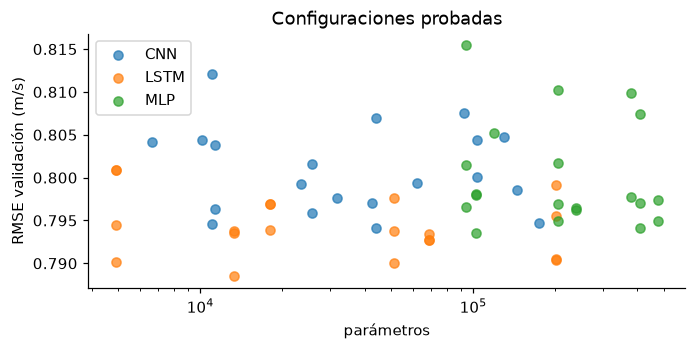

In [4]:
aj = pd.DataFrame(json.load(open("resultados/ajuste.json")))
print(aj.groupby("modelo").agg(configuraciones=("rmse_val", "size"), mejor=("rmse_val", "min"),
                               mediana=("rmse_val", "median"), peor=("rmse_val", "max"),
                               minutos=("segundos", lambda s: s.sum() / 60)).round(4))
print("\nHiperparámetros elegidos:"); print(json.dumps(json.load(open("configs/hiperparametros.json")), indent=1))
fig, ax = plt.subplots(figsize=(7, 3))
for m, g in aj.groupby("modelo"):
    ax.scatter(g.parametros, g.rmse_val, label=m, alpha=.7)
ax.set(xscale="log", xlabel="parámetros", ylabel="RMSE validación (m/s)", title="Configuraciones probadas")
ax.legend(); plt.show()

## Corridas definitivas: curvas de aprendizaje

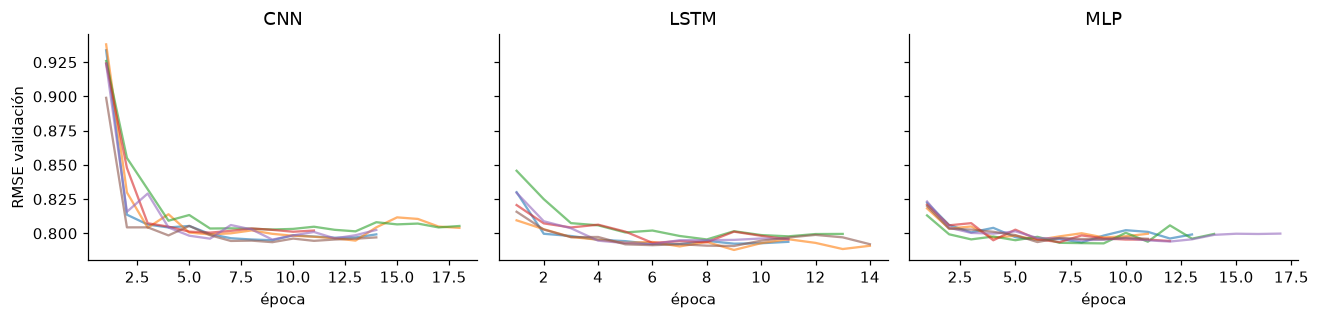

        RMSE_val      de   epocas  segundos  parametros
modelo                                                 
CNN       0.7968  0.0033  14.8333   30.5340       44129
LSTM      0.7919  0.0025  12.3333   57.7265       13345
MLP       0.7937  0.0008  13.0000    6.4285      102785


In [5]:
co = pd.DataFrame(json.load(open("resultados/corridas.json")))
fig, ax = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for a_, (m, g) in zip(ax, co.groupby("modelo")):
    for h in g.historia:
        a_.plot(range(1, len(h) + 1), h, alpha=.6)
    a_.set(title=m, xlabel="época"); ax[0].set_ylabel("RMSE validación")
plt.tight_layout(); plt.show()
print(co.groupby("modelo").agg(RMSE_val=("rmse_val", "mean"), de=("rmse_val", "std"), epocas=("epocas", "mean"),
                               segundos=("segundos", "mean"), parametros=("parametros", "first")).round(4))

## Sensibilidad: con presión como quinta variable

En el EDA se descartó la presión por su faltante no aleatorio. Para medir cuánto se pierde, se repitió el
entrenamiento con la configuración `configs/datos_con_presion.json` (3 semillas por modelo, solo validación).
Como esa configuración tiene menos estaciones, la comparación es orientativa.

In [6]:
import os
if os.path.exists("resultados/sensibilidad_presion.json"):
    se = pd.DataFrame(json.load(open("resultados/sensibilidad_presion.json")))
    comp = pd.DataFrame({"sin presión (4 variables)": co.groupby("modelo").rmse_val.mean(),
                         "con presión (5 variables)": se.groupby("modelo").rmse_val.mean()})
    print(comp.round(4))

        sin presión (4 variables)  con presión (5 variables)
modelo                                                      
CNN                        0.7968                     0.8151
LSTM                       0.7919                     0.8084
MLP                        0.7937                     0.8095
